In [1]:
import nflreadpy as nfl
from nflreadpy.config import update_config
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# Read in core data
plays = pd.read_csv("data_core_raw.csv")

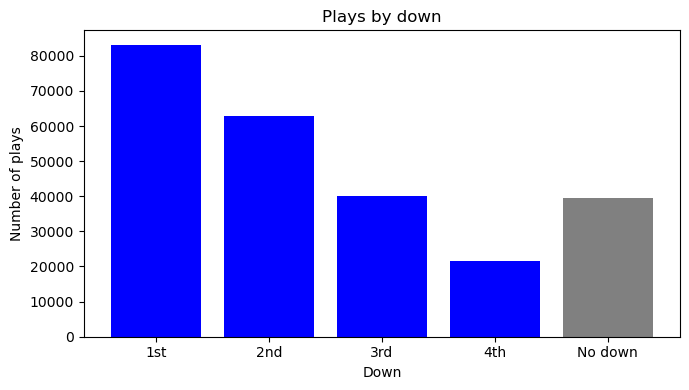

In [3]:
# Plot downs - "No down" includes kickoffs, extra points, timeouts etc
down_ct = (plays["down"].map({1: "1st", 2: "2nd", 3: "3rd", 4: "4th"}).fillna("No down")
               .value_counts().reindex(["1st", "2nd", "3rd", "4th", "No down"]))
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(down_ct.index, down_ct.values, color=["blue","blue","blue","blue","gray"])
ax.set_ylabel("Number of plays")
ax.set_title("Plays by down")
ax.set_xlabel("Down") 
plt.tight_layout()
plt.show()

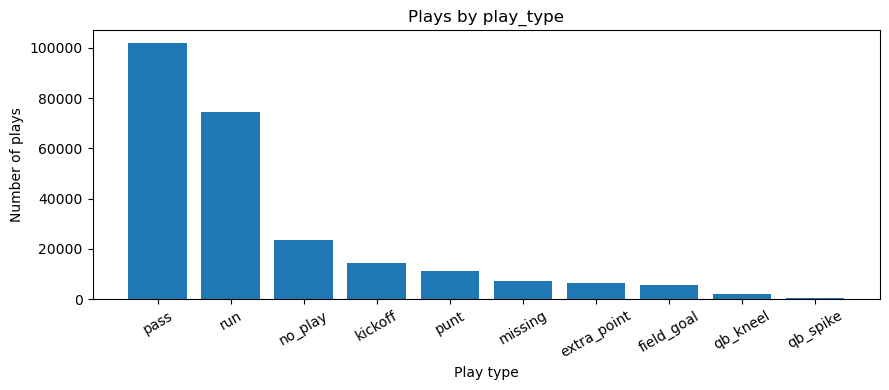

In [4]:
# Plot play types - 'No play' includes penalties, while 'missing' includes timeouts, end of quarte etc
pt_counts = plays["play_type"].fillna("missing").replace("", "missing").value_counts()
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(pt_counts.index, pt_counts.values)
ax.set_ylabel("Number of plays")
ax.set_title("Plays by play_type")
ax.set_xlabel("Play type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

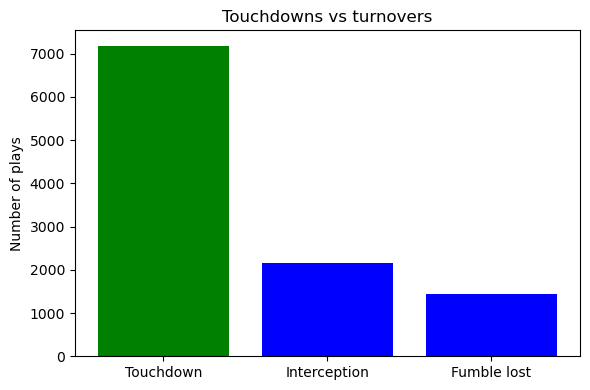

In [5]:
# Plot touchdowns vs interceptions vs fumbles lost
out_counts = {
    "Touchdown": int((plays["touchdown"] == 1).sum()),
    "Interception": int((plays["interception"] == 1).sum()),
    "Fumble lost": int((plays["fumble_lost"] == 1).sum())}
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(out_counts.keys(), out_counts.values(), color=["green", "blue", "blue"])
ax.set_ylabel("Number of plays")
ax.set_title("Touchdowns vs turnovers")
plt.tight_layout()
plt.show()

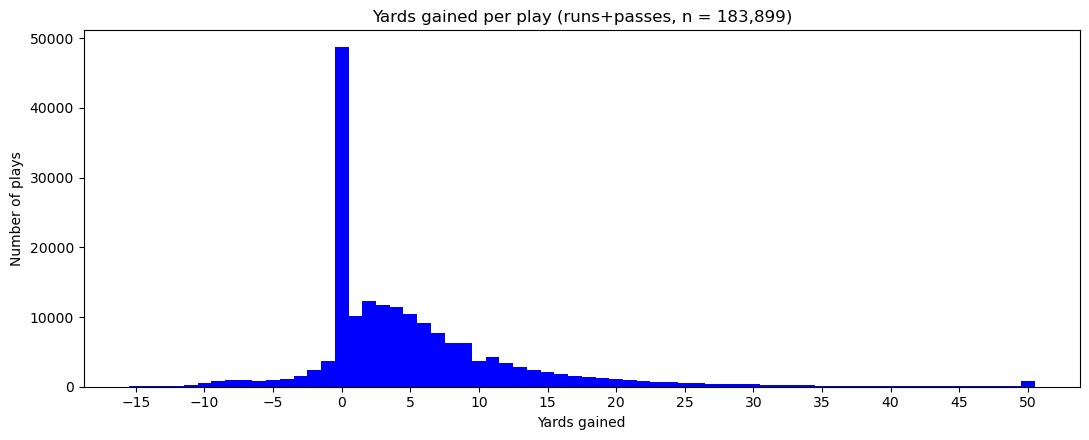

In [6]:
# Plot yards gained
yards_gained = plays.loc[(plays["pass"] == 1) | (plays["rush"] == 1), "yards_gained"].dropna().clip(-15, 50)
fig, ax = plt.subplots(figsize=(11, 4.5))
counts, edges, _ = ax.hist(yards_gained, bins=np.arange(-15.5, 51.5, 1), color="blue", linewidth=0.5)
ax.set_title(f"Yards gained per play (runs+passes, n = {len(yards_gained):,})")
ax.set_ylabel("Number of plays")
ax.set_xlabel("Yards gained")
ax.set_xticks(range(-15, 51, 5))
plt.tight_layout()
plt.show()